# Register STAC metadata

Select three STAC items from DLR's Geoservice, publish them as an OCI package, and serve them from a workspace STAC API. Clients can query the selected items while the raster files remain at the source.

The notebook checks package file hashes after registry transfer and deployment. It also checks the API items, source geometry, and asset URLs.

Create a workspace with [Workspace Management](../workspace-management.ipynb) first. Use [Vienna imagery](vienna-imagery-with-stac-and-s3.ipynb) when you want to copy image files into workspace storage too.


## Data flow

[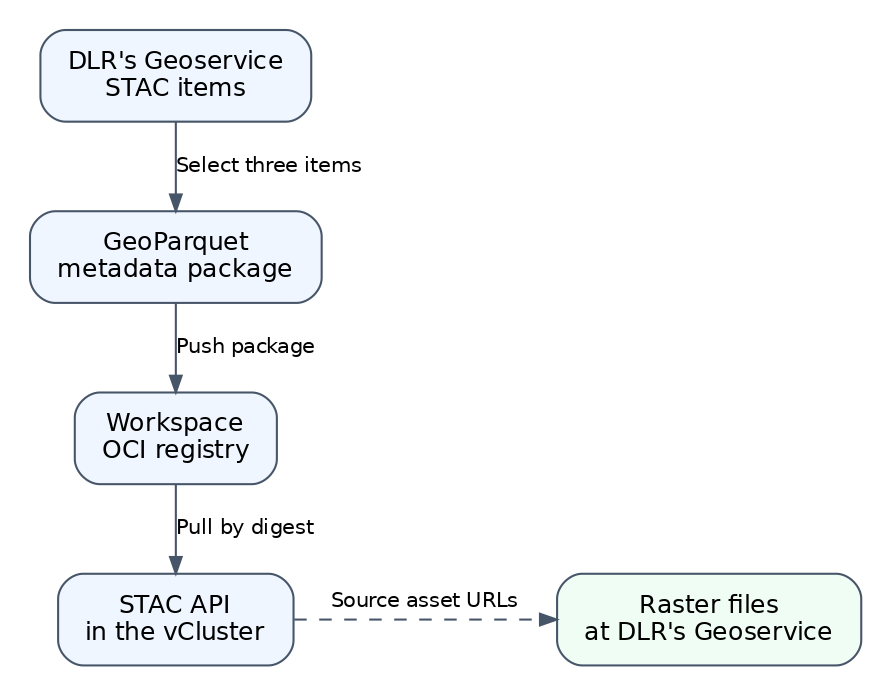](../img/register-stac-metadata/data-flow.svg)


## 1. Configure the workspace

Use the test workspace created with [Workspace Management](../workspace-management.ipynb). Start its `default` Datalab session from the workspace dashboard and run this notebook there.

The session supplies `KUBECONFIG`, `REGISTRY_HOST`, `REGISTRY_USERNAME`, and `REGISTRY_PASSWORD`. Set `EOEPCA_WORKSPACE` to the test workspace name and `EOEPCA_SESSION=default` before starting Jupyter. For a local kernel, supply the same settings and a kubeconfig for that session's vCluster.

Registry access uses its supplied Basic credentials. These credentials are separate from user device login.

From the repository checkout, install the dependencies and start Jupyter:

```bash
uv sync
uv run jupyter lab docs/getting-started/register-stac-metadata.ipynb
```

Command, retry, and checksum functions are in the [shared notebook helper](../notebook_support.py).


In [2]:
from __future__ import annotations

import json
import os
import shutil
import subprocess
import time
import tempfile
import sys
from datetime import datetime, timezone
from pathlib import Path

import pystac
import requests
import stacpkg.oci as stacpkg_oci
from IPython.display import Markdown, display
from pystac_client import Client

REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "docs/notebook_support.py").is_file()
)
sys.path.insert(0, str(REPO_ROOT / "docs"))
from notebook_support import (
    kubectl_apply, pipe, render_manifest, require_environment, run, sha256,
)

WORKSPACE_NAME = os.environ["EOEPCA_WORKSPACE"]
SESSION_NAME = os.getenv("EOEPCA_SESSION", "default")

REGISTRY_HOST = os.getenv("REGISTRY_HOST")
REGISTRY_USERNAME = os.getenv("REGISTRY_USERNAME")
REGISTRY_PASSWORD = os.getenv("REGISTRY_PASSWORD")

WORK_DIR = Path(tempfile.mkdtemp(prefix="test-"))
STACPKG = str(Path(sys.executable).with_name("stacpkg"))
PACKAGE_DIR = WORK_DIR / "package"
PULLED_DIR = WORK_DIR / "pulled-package"
API_NAME = "cng-stac-api"
REGISTRY_SECRET = f"{API_NAME}-registry"
INIT_CONFIG = f"{API_NAME}-init"
MANIFEST_DIR = Path(
    os.getenv(
        "EOEPCA_MANIFEST_DIR",
        "docs/getting-started/register-stac-metadata",
    )
)
if not MANIFEST_DIR.is_dir() and Path("register-stac-metadata").is_dir():
    MANIFEST_DIR = Path("register-stac-metadata")

WORK_DIR.mkdir(parents=True, exist_ok=True)

print(
    {
        "workspace": WORKSPACE_NAME,
        "session": SESSION_NAME,
        "registry_host": REGISTRY_HOST,
        "registry_credentials_loaded": bool(
            REGISTRY_HOST and REGISTRY_USERNAME and REGISTRY_PASSWORD
        ),
    }
)

{'workspace': 'ws-test-20261024071434', 'session': 'default', 'registry_host': 'registry-ws-test-20261024071434-default.lab.develop-v2.eoepca.org', 'registry_credentials_loaded': True}


In [3]:
require_environment(
    "EOEPCA_WORKSPACE",
    "KUBECONFIG",
    "REGISTRY_HOST",
    "REGISTRY_USERNAME",
    "REGISTRY_PASSWORD",
)

# Use the standard ORAS variable names.
os.environ["ORAS_USER"] = REGISTRY_USERNAME
os.environ["ORAS_PASS"] = REGISTRY_PASSWORD
# Refuse the host-cluster kubeconfig. All workloads belong in this vCluster.
if Path(os.environ["KUBECONFIG"]).expanduser().name == "config-eoepca-demo":
    raise ValueError("Use the test session vCluster kubeconfig, not the host cluster.")

# Use SPDY for vCluster streaming commands.
os.environ["KUBECTL_REMOTE_COMMAND_WEBSOCKETS"] = "false"
os.environ["KUBECTL_PORT_FORWARD_WEBSOCKETS"] = "false"


## 2. Select STAC Items

The collection on DLR's Geoservice has global daily rasters. The bounding box selects intersecting Items; it does not crop the images. Keep each Item's original geometry and projection fields.

STAC time searches also match intersecting intervals. A 31 July Item can match an August search if its interval crosses midnight. Filter on the Item's representative `datetime` to select the three days used here.


In [4]:
SOURCE_API = "https://geoservice.dlr.de/eoc/ogc/stac/v1/"
SOURCE_COLLECTION = "S5P_TROPOMI_L3_P1D_CF_v2"
EUROPE_BBOX = [-10.0, 35.0, 30.0, 70.0]
START = datetime(2023, 8, 1, tzinfo=timezone.utc)
END = datetime(2023, 8, 3, 23, 59, 59, tzinfo=timezone.utc)
SEARCH_INTERVAL = "2023-08-01T00:00:00Z/2023-08-03T23:59:59Z"

catalog = Client.open(SOURCE_API)
candidates = list(
    catalog.search(
        collections=[SOURCE_COLLECTION],
        bbox=EUROPE_BBOX,
        datetime=SEARCH_INTERVAL,
        limit=20,
    ).items()
)

items = sorted(
    [
        item
        for item in candidates
        if item.datetime is not None and START <= item.datetime <= END
    ],
    key=lambda item: item.datetime,
)[:3]

if len(items) != 3:
    raise RuntimeError(f"Expected three post-filtered source Items, got {len(items)}")

print(
    [
        {
            "id": item.id,
            "datetime": item.datetime.isoformat(),
            "bbox": item.bbox,
            "proj:shape": item.properties.get("proj:shape"),
        }
        for item in items
    ]
)

[{'id': 'S5P_DLR_OFFL_01_L3_CF_20230801', 'datetime': '2023-08-01T12:31:25.784500+00:00', 'bbox': [-180.0, -90.0, 180.0, 90.0], 'proj:shape': [1800, 3600]}, {'id': 'S5P_DLR_OFFL_01_L3_CF_20230802', 'datetime': '2023-08-02T12:12:17.578500+00:00', 'bbox': [-180.0, -90.0, 180.0, 90.0], 'proj:shape': [1800, 3600]}, {'id': 'S5P_DLR_OFFL_01_L3_CF_20230803', 'datetime': '2023-08-03T12:43:54.323000+00:00', 'bbox': [-180.0, -90.0, 180.0, 90.0], 'proj:shape': [1800, 3600]}]


In [5]:
item_collection = pystac.ItemCollection(items)
# Point the API at the local GeoParquet file.
index_bbox = [
    min(item.bbox[0] for item in items),
    min(item.bbox[1] for item in items),
    max(item.bbox[2] for item in items),
    max(item.bbox[3] for item in items),
]
index_start = min(
    item.common_metadata.start_datetime or item.datetime for item in items
)
index_end = max(
    item.common_metadata.end_datetime or item.datetime for item in items
)
index_collection = pystac.Collection(
    id=SOURCE_COLLECTION,
    description="Materialized STAC GeoParquet index of selected source Items.",
    extent=pystac.Extent(
        spatial=pystac.SpatialExtent([index_bbox]),
        temporal=pystac.TemporalExtent([[index_start, index_end]]),
    ),
    license="other",
)
index_collection.add_asset(
    "items",
    pystac.Asset(
        href="items.parquet",
        media_type="application/vnd.apache.parquet",
        roles=["data"],
    ),
)
collections_document = [index_collection.to_dict()]
print(
    f"Prepared {len(items)} unmodified source Items and the technical "
    "API collection document in memory"
)

Prepared 3 unmodified source Items and the technical API collection document in memory


## 3. Build the package

Build from the selected Items. The package contains:

- `items.parquet`: the STAC items as GeoParquet.
- `assets.lock.parquet`: source asset URLs and available object metadata.
- `collections.json`: the API collection document, pointing to `items.parquet`.

`--no-probe-metadata` skips requests for source object headers. The source files are not copied.


In [6]:
if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)

pipe(
    [STACPKG, "items", "from-json"],
    [
        STACPKG,
        "build",
        "--no-probe-metadata",
        str(PACKAGE_DIR),
    ],
    input_text=json.dumps(item_collection.to_dict()),
)
(PACKAGE_DIR / "collections.json").write_text(
    json.dumps(collections_document, indent=2),
    encoding="utf-8",
)
run([STACPKG, "inspect", "--format", "markdown", str(PACKAGE_DIR)])

local_hashes = {
    path.name: sha256(path)
    for path in sorted(PACKAGE_DIR.iterdir())
    if path.is_file() and path.name != "manifest.json"
}
print({"package_sha256": local_hashes})

# stacpkg Inspect

- Package: `/tmp/test-x2x44p_u/package`
- Items: 3
- Collections: S5P_TROPOMI_L3_P1D_CF_v2
- Assets: 15
- Asset keys: cf, data, overview, quicklook, thumbnail
- Known asset bytes: 0

## Files

- `assets.lock.parquet` (application/vnd.apache.parquet, 3506 bytes)
- `collections.json` (application/json, 751 bytes)
- `items.parquet` (application/vnd.apache.parquet, 37271 bytes)
{'package_sha256': {'assets.lock.parquet': '3db0d383af51b22fd33ad19faf8813ac7943c887a50f29af8ff8a91f3ad5e72a', 'collections.json': 'aaf62165b18f1ee88c4c3b5c20ab1a9bdc511ee46f64abc0e2bca8948e074ba5', 'items.parquet': 'dab70a32cf2a4822b104d79daefbb19929651f88dbc45b00683f204abef91f25'}}


## 4. Publish to the OCI registry

Push the package to the session registry. The tag includes part of the Item-table checksum so it is easier to identify.


In [7]:
OCI_REPOSITORY = "cng-resource-registration/s5p-cloud-fraction"

content_tag = local_hashes["items.parquet"][:16]
tagged_reference = f"{REGISTRY_HOST}/{OCI_REPOSITORY}:sha256-{content_tag}"
stacpkg_oci.push_package(
    PACKAGE_DIR,
    tagged_reference,
    auth_backend="basic",
)
print({"published_reference": tagged_reference})

{'published_reference': 'registry-ws-test-20261024071434-default.lab.develop-v2.eoepca.org/cng-resource-registration/s5p-cloud-fraction:sha256-dab70a32cf2a4822'}


### Check the published package

Tags can be reassigned. Resolve the tag to a manifest digest and pull by that digest. Compare each downloaded file's SHA-256 with its value before the push.

This checks the metadata package, not the raster files at the source URLs. It does not authenticate the publisher.


In [8]:
registry_auth = (REGISTRY_USERNAME, REGISTRY_PASSWORD)
manifest_headers = {
    "Accept": "application/vnd.oci.image.manifest.v1+json"
}
tagged_manifest_url = (
    f"https://{REGISTRY_HOST}/v2/{OCI_REPOSITORY}/"
    f"manifests/sha256-{content_tag}"
)
manifest_response = requests.head(
    tagged_manifest_url,
    auth=registry_auth,
    headers=manifest_headers,
    timeout=30,
)
manifest_response.raise_for_status()
manifest_digest = manifest_response.headers["Docker-Content-Digest"]
oci_digest_reference = (
    f"{REGISTRY_HOST}/{OCI_REPOSITORY}@{manifest_digest}"
)

tags_response = requests.get(
    f"https://{REGISTRY_HOST}/v2/{OCI_REPOSITORY}/tags/list",
    auth=registry_auth,
    timeout=30,
)
tags_response.raise_for_status()
manifest_document_response = requests.get(
    (
        f"https://{REGISTRY_HOST}/v2/{OCI_REPOSITORY}/"
        f"manifests/{manifest_digest}"
    ),
    auth=registry_auth,
    headers=manifest_headers,
    timeout=30,
)
manifest_document_response.raise_for_status()
manifest_document = manifest_document_response.json()
registry_contents = {
    "repository": OCI_REPOSITORY,
    "tags": sorted(tags_response.json().get("tags") or []),
    "resolved_reference": oci_digest_reference,
    "artifact_type": manifest_document.get("artifactType"),
    "layers": [
        {
            "name": (layer.get("annotations") or {}).get(
                "org.opencontainers.image.title"
            ),
            "media_type": layer.get("mediaType"),
            "digest": layer.get("digest"),
            "size_bytes": layer.get("size"),
        }
        for layer in manifest_document.get("layers", [])
    ],
}
print(json.dumps({"registry_contents": registry_contents}, indent=2))

if PULLED_DIR.exists():
    shutil.rmtree(PULLED_DIR)
stacpkg_oci.pull_package(
    oci_digest_reference,
    PULLED_DIR,
    auth_backend="basic",
)

pulled_hashes = {
    path.name: sha256(path)
    for path in sorted(PULLED_DIR.iterdir())
    if path.is_file() and path.name != "manifest.json"
}
assert pulled_hashes == local_hashes
print(
    {
        "oci_reference": oci_digest_reference,
        "package_sha256": pulled_hashes,
        "round_trip_verified": True,
    }
)

{
  "registry_contents": {
    "repository": "cng-resource-registration/s5p-cloud-fraction",
    "tags": [
      "sha256-dab70a32cf2a4822"
    ],
    "resolved_reference": "registry-ws-test-20261024071434-default.lab.develop-v2.eoepca.org/cng-resource-registration/s5p-cloud-fraction@sha256:58aa6fbc744c64551f673f0ff5c5906235b084a47cb2163661b8013ad9d6f25c",
    "artifact_type": "application/vnd.stacpkg.package.v1+json",
    "layers": [
      {
        "name": "items.parquet",
        "media_type": "application/vnd.stacpkg.items.v1.parquet",
        "digest": "sha256:dab70a32cf2a4822b104d79daefbb19929651f88dbc45b00683f204abef91f25",
        "size_bytes": 37271
      },
      {
        "name": "assets.lock.parquet",
        "media_type": "application/vnd.stacpkg.asset-lock.v1.parquet",
        "digest": "sha256:3db0d383af51b22fd33ad19faf8813ac7943c887a50f29af8ff8a91f3ad5e72a",
        "size_bytes": 3506
      },
      {
        "name": "collections.json",
        "media_type": "application

{'oci_reference': 'registry-ws-test-20261024071434-default.lab.develop-v2.eoepca.org/cng-resource-registration/s5p-cloud-fraction@sha256:58aa6fbc744c64551f673f0ff5c5906235b084a47cb2163661b8013ad9d6f25c', 'package_sha256': {'assets.lock.parquet': '3db0d383af51b22fd33ad19faf8813ac7943c887a50f29af8ff8a91f3ad5e72a', 'collections.json': 'aaf62165b18f1ee88c4c3b5c20ab1a9bdc511ee46f64abc0e2bca8948e074ba5', 'items.parquet': 'dab70a32cf2a4822b104d79daefbb19929651f88dbc45b00683f204abef91f25'}, 'round_trip_verified': True}


## 5. Start the STAC API

Apply the manifests in `register-stac-metadata/` to the vCluster. The init container uses the `cng-stac-api-registry` Secret to pull the package into an `emptyDir` volume. The API then reads `/data/collections.json` and `/data/items.parquet` from that volume.

Other workloads in the vCluster can reach it at:

`http://cng-stac-api.default.svc.cluster.local`

After rollout, compare the checksums inside the API container with the original package files.


In [9]:
manifest_paths = sorted(MANIFEST_DIR.glob("*.yaml"))
if not manifest_paths:
    raise FileNotFoundError(f"No Kubernetes manifests found in {MANIFEST_DIR}")

manifest_values = {
    "REGISTRY_HOST": REGISTRY_HOST,
    "REGISTRY_USERNAME": REGISTRY_USERNAME,
    "REGISTRY_PASSWORD": REGISTRY_PASSWORD,
    "OCI_REFERENCE": oci_digest_reference,
}
display_values = {
    **manifest_values,
    "REGISTRY_USERNAME": "<redacted>",
    "REGISTRY_PASSWORD": "<redacted>",
}

rendered_manifests = []
for manifest_path in manifest_paths:
    template = manifest_path.read_text(encoding="utf-8")
    display_manifest = render_manifest(template, display_values)
    display(
        Markdown(
            f"### `{manifest_path.name}`\n\n"
            f"```yaml\n{display_manifest.rstrip()}\n```"
        )
    )
    rendered_manifests.append(render_manifest(template, manifest_values))

kubectl_apply("\n---\n".join(rendered_manifests))

run(
    [
        "kubectl",
        "rollout",
        "status",
        f"deployment/{API_NAME}",
        "--timeout=5m",
    ],
    attempts=6,
)
run(
    [
        "kubectl",
        "get",
        "deployment,service,pod",
        "-l",
        f"app={API_NAME}",
        "-o",
        "wide",
    ]
)
staged_files_script = """
import hashlib
import json
from pathlib import Path

files = []
for path in sorted(Path('/data').iterdir()):
    if path.is_file():
        files.append(
            {
                'name': path.name,
                'size_bytes': path.stat().st_size,
                'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
            }
        )
print(json.dumps({'staged_files': files}, indent=2))
"""
staged_result = run(
    [
        "kubectl",
        "exec",
        f"deployment/{API_NAME}",
        "-c",
        "api",
        "--",
        "python",
        "-c",
        staged_files_script,
    ]
)
staged_files = json.loads(staged_result.stdout)["staged_files"]
staged_hashes = {
    entry["name"]: entry["sha256"] for entry in staged_files
}
assert staged_hashes == local_hashes
print({"staged_hashes_match_package": True})

### `01-registry-secret.yaml`

```yaml
apiVersion: v1
kind: Secret
metadata:
  name: cng-stac-api-registry
  labels:
    app: cng-stac-api
type: Opaque
stringData:
  host: "registry-ws-test-20261024071434-default.lab.develop-v2.eoepca.org"
  username: "<redacted>"
  password: "<redacted>"
  reference: "registry-ws-test-20261024071434-default.lab.develop-v2.eoepca.org/cng-resource-registration/s5p-cloud-fraction@sha256:58aa6fbc744c64551f673f0ff5c5906235b084a47cb2163661b8013ad9d6f25c"
```

### `02-pull-script-configmap.yaml`

```yaml
apiVersion: v1
kind: ConfigMap
metadata:
  name: cng-stac-api-init
  labels:
    app: cng-stac-api
data:
  pull.py: |
    import os

    import stacpkg.oci as stacpkg_oci


    os.environ["ORAS_USER"] = os.environ["REGISTRY_USERNAME"]
    os.environ["ORAS_PASS"] = os.environ["REGISTRY_PASSWORD"]
    stacpkg_oci.pull_package(
        os.environ["OCI_REFERENCE"],
        "/data",
        auth_backend="basic",
    )
```

### `03-service.yaml`

```yaml
apiVersion: v1
kind: Service
metadata:
  name: cng-stac-api
  labels:
    app: cng-stac-api
spec:
  selector:
    app: cng-stac-api
  ports:
    - name: http
      port: 80
      targetPort: http
```

### `04-deployment.yaml`

```yaml
apiVersion: apps/v1
kind: Deployment
metadata:
  name: cng-stac-api
  labels:
    app: cng-stac-api
spec:
  replicas: 1
  selector:
    matchLabels:
      app: cng-stac-api
  template:
    metadata:
      labels:
        app: cng-stac-api
    spec:
      initContainers:
        - name: pull-stac-package
          image: python@sha256:4c2cf9917bd1cbacc5e9b07320025bdb7cdf2df7b0ceaccb55e9dd7e30987419
          command:
            - /bin/sh
            - -c
          args:
            - >-
              python -m pip install --no-cache-dir
              'stacpkg==0.1.4'
              'oras==0.2.42'
              && exec python /scripts/pull.py
          env:
            - name: REGISTRY_HOST
              valueFrom:
                secretKeyRef:
                  name: cng-stac-api-registry
                  key: host
            - name: REGISTRY_USERNAME
              valueFrom:
                secretKeyRef:
                  name: cng-stac-api-registry
                  key: username
            - name: REGISTRY_PASSWORD
              valueFrom:
                secretKeyRef:
                  name: cng-stac-api-registry
                  key: password
            - name: OCI_REFERENCE
              valueFrom:
                secretKeyRef:
                  name: cng-stac-api-registry
                  key: reference
          volumeMounts:
            - name: data
              mountPath: /data
            - name: init-script
              mountPath: /scripts
              readOnly: true
          resources:
            requests:
              cpu: 100m
              memory: 128Mi
            limits:
              cpu: "1"
              memory: 512Mi
          securityContext:
            allowPrivilegeEscalation: false
            capabilities:
              drop:
                - ALL
      containers:
        - name: api
          image: python@sha256:4c2cf9917bd1cbacc5e9b07320025bdb7cdf2df7b0ceaccb55e9dd7e30987419
          command:
            - /bin/sh
            - -c
          args:
            - >-
              python -m pip install --no-cache-dir
              'stac-fastapi-geoparquet[serve]==0.0.6'
              'stac-fastapi-api==6.2.0'
              'stac-fastapi-extensions==6.2.0'
              'stac-fastapi-types==6.2.0'
              'fastapi==0.128.0'
              'starlette==0.50.0'
              'pydantic==2.12.5'
              'pydantic-settings==2.12.0'
              'uvicorn==0.40.0'
              'geojson-pydantic==2.1.0'
              'stac-pydantic==3.4.0'
              'rustac==0.9.3'
              'obstore==0.8.2'
              && exec python -m uvicorn
              stac_fastapi.geoparquet.main:app
              --host 0.0.0.0
              --port 8000
              --root-path "${ROOT_PATH}"
          env:
            - name: STAC_FASTAPI_COLLECTIONS_HREF
              value: /data/collections.json
            - name: ROOT_PATH
              value: /proxy/8000
          ports:
            - name: http
              containerPort: 8000
          readinessProbe:
            httpGet:
              path: /
              port: http
            periodSeconds: 5
            failureThreshold: 30
          volumeMounts:
            - name: data
              mountPath: /data
              readOnly: true
          resources:
            requests:
              cpu: 100m
              memory: 256Mi
            limits:
              cpu: "1"
              memory: 1Gi
          securityContext:
            allowPrivilegeEscalation: false
            capabilities:
              drop:
                - ALL
      volumes:
        - name: data
          emptyDir: {}
        - name: init-script
          configMap:
            name: cng-stac-api-init
      securityContext:
        seccompProfile:
          type: RuntimeDefault
```

secret/cng-stac-api-registry configured
configmap/cng-stac-api-init unchanged
service/cng-stac-api unchanged
deployment.apps/cng-stac-api unchanged


deployment "cng-stac-api" successfully rolled out


NAME                           READY   UP-TO-DATE   AVAILABLE   AGE   CONTAINERS   IMAGES                                                                           SELECTOR
deployment.apps/cng-stac-api   1/1     1            1           62m   api          python@sha256:4c2cf9917bd1cbacc5e9b07320025bdb7cdf2df7b0ceaccb55e9dd7e30987419   app=cng-stac-api

NAME                   TYPE        CLUSTER-IP      EXTERNAL-IP   PORT(S)   AGE   SELECTOR
service/cng-stac-api   ClusterIP   10.43.210.172   <none>        80/TCP    62m   app=cng-stac-api

NAME                               READY   STATUS    RESTARTS   AGE   IP            NODE                         NOMINATED NODE   READINESS GATES
pod/cng-stac-api-594b85479-7s8g2   1/1     Running   0          62m   10.42.3.144   rke2-worker-node-0-74c7e90   <none>           <none>


{
  "staged_files": [
    {
      "name": "assets.lock.parquet",
      "size_bytes": 3506,
      "sha256": "3db0d383af51b22fd33ad19faf8813ac7943c887a50f29af8ff8a91f3ad5e72a"
    },
    {
      "name": "collections.json",
      "size_bytes": 751,
      "sha256": "aaf62165b18f1ee88c4c3b5c20ab1a9bdc511ee46f64abc0e2bca8948e074ba5"
    },
    {
      "name": "items.parquet",
      "size_bytes": 37271,
      "sha256": "dab70a32cf2a4822b104d79daefbb19929651f88dbc45b00683f204abef91f25"
    }
  ]
}
{'staged_hashes_match_package': True}


## 6. Query the API

Use a port-forward to reach the internal Service from the notebook. The cell checks the API and prints browser links through the editor proxy at `/proxy/<port>/`.

Use those printed URLs: links returned by the API omit the proxy prefix. Keep the Jupyter kernel running while using the browser links. Workloads in the vCluster can use the Service URL directly.


In [10]:
LOCAL_API_PORT = int(os.getenv("EOEPCA_API_PORT", "8000"))

if "port_forward" in globals() and port_forward.poll() is None:
    port_forward.terminate()
    port_forward.wait(timeout=10)

def start_port_forward():
    return subprocess.Popen(
        [
            "kubectl",
            "port-forward",
            f"service/{API_NAME}",
            f"{LOCAL_API_PORT}:80",
        ],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
        text=True,
    )


port_forward = start_port_forward()
api_root = f"http://127.0.0.1:{LOCAL_API_PORT}"
for attempt in range(60):
    try:
        root_response = requests.get(api_root, timeout=2)
        root_response.raise_for_status()
        break
    except requests.RequestException:
        if port_forward.poll() is not None:
            port_forward = start_port_forward()
        time.sleep(1)
else:
    raise TimeoutError("STAC API did not become ready within 60 seconds")

collection_path = f"/collections/{SOURCE_COLLECTION}"
first_item_id = items[0].id
requests_to_check = {
    "conformance": requests.get(f"{api_root}/conformance", timeout=10),
    "collections": requests.get(f"{api_root}/collections", timeout=10),
    "collection": requests.get(f"{api_root}{collection_path}", timeout=10),
    "collection_items": requests.get(
        f"{api_root}{collection_path}/items",
        params={"limit": len(items)},
        timeout=30,
    ),
    "item": requests.get(
        f"{api_root}{collection_path}/items/{first_item_id}",
        timeout=30,
    ),
    "search": requests.post(
        f"{api_root}/search",
        json={"collections": [SOURCE_COLLECTION], "limit": 2},
        timeout=30,
    ),
}
for response in requests_to_check.values():
    response.raise_for_status()

collections_document = requests_to_check["collections"].json()
collection_document = requests_to_check["collection"].json()
collection_items = requests_to_check["collection_items"].json()["features"]
item_document = requests_to_check["item"].json()
returned_features = requests_to_check["search"].json()["features"]
expected_item_ids = {item.id for item in items}

assert collection_document["id"] == SOURCE_COLLECTION
assert {feature["id"] for feature in collection_items} == expected_item_ids
assert item_document["id"] == first_item_id
assert len(returned_features) == 2
assert {feature["id"] for feature in returned_features} <= expected_item_ids

source_by_id = {item.id: item for item in items}
for feature in collection_items:
    original = source_by_id[feature["id"]]
    assert feature["bbox"] == original.bbox
    assert feature["geometry"] == original.geometry
    assert {key: asset["href"] for key, asset in feature["assets"].items()} == {
        key: asset.href for key, asset in original.assets.items()
    }

browser_proxy_root = None
if os.getenv("SESSION_NAME") and os.getenv("INGRESS_DOMAIN"):
    ingress_protocol = os.getenv("INGRESS_PROTOCOL", "https")
    browser_proxy_root = (
        f"{ingress_protocol}://editor-{os.environ['SESSION_NAME']}."
        f"{os.environ['INGRESS_DOMAIN']}/proxy/{LOCAL_API_PORT}"
    )

print(
    {
        "endpoint_status": {
            "root": root_response.status_code,
            **{
                name: response.status_code
                for name, response in requests_to_check.items()
            },
        },
        "stac_version": root_response.json()["stac_version"],
        "source_geometry_preserved": True,
        "source_asset_urls_preserved": True,
        "collection_ids": [
            collection["id"]
            for collection in collections_document["collections"]
        ],
        "collection_item_ids": [
            feature["id"] for feature in collection_items
        ],
        "search_item_ids": [feature["id"] for feature in returned_features],
        "browser_urls": (
            {
                "root": f"{browser_proxy_root}/",
                "conformance": f"{browser_proxy_root}/conformance",
                "collections": f"{browser_proxy_root}/collections",
                "collection": f"{browser_proxy_root}{collection_path}",
                "collection_items": (
                    f"{browser_proxy_root}{collection_path}/items"
                ),
                "first_item": (
                    f"{browser_proxy_root}{collection_path}/items/"
                    f"{first_item_id}"
                ),
            }
            if browser_proxy_root
            else "Use the VS Code Ports tab for the forwarded local port."
        ),
    }
)

{'endpoint_status': {'root': 200, 'conformance': 200, 'collections': 200, 'collection': 200, 'collection_items': 200, 'item': 200, 'search': 200}, 'stac_version': '1.0.0', 'source_geometry_preserved': True, 'source_asset_urls_preserved': True, 'collection_ids': ['S5P_TROPOMI_L3_P1D_CF_v2'], 'collection_item_ids': ['S5P_DLR_OFFL_01_L3_CF_20230801', 'S5P_DLR_OFFL_01_L3_CF_20230802', 'S5P_DLR_OFFL_01_L3_CF_20230803'], 'search_item_ids': ['S5P_DLR_OFFL_01_L3_CF_20230801', 'S5P_DLR_OFFL_01_L3_CF_20230802'], 'browser_urls': 'Use the VS Code Ports tab for the forwarded local port.'}


## 7. Keep or remove the demo API

By default, the API remains available in the vCluster and the OCI package stays in the registry. The local port-forward lasts while the notebook kernel is running.

Set `EOEPCA_CLEAN_UP=1` to remove the API workload, Service, init script, and registry Secret. The package remains in the registry.


In [11]:
if os.getenv("EOEPCA_CLEAN_UP", "0") == "1":
    if "port_forward" in globals() and port_forward.poll() is None:
        port_forward.terminate()
        try:
            port_forward.wait(timeout=10)
        except subprocess.TimeoutExpired:
            port_forward.kill()
    run(
        [
            "kubectl",
            "delete",
            f"deployment/{API_NAME}",
            f"service/{API_NAME}",
            f"configmap/{INIT_CONFIG}",
            f"secret/{REGISTRY_SECRET}",
            "--ignore-not-found",
        ],
        attempts=6,
    )
else:
    print(
        "Temporary API retained. The port-forward remains available while "
        "this Jupyter kernel is running; set EOEPCA_CLEAN_UP=1 to remove "
        "the temporary API resources."
    )

Temporary API retained. The port-forward remains available while this Jupyter kernel is running; set EOEPCA_CLEAN_UP=1 to remove the temporary API resources.


## Result and next step

The workspace now serves three selected STAC items from a package identified by its OCI digest. Their geometry and asset URLs match the source. Clients still read raster data from DLR's Geoservice.

To keep image files in workspace storage, copy them, check their hashes, and update the STAC asset links. The [Vienna notebook](vienna-imagery-with-stac-and-s3.ipynb) shows image preparation and upload.
